# Primer Parcial 2026-2C — ¿La casa paga comisión?

Seguimos explícitamente el **workflow de un modelo predictivo**:

| # | Etapa | Qué hacemos en este notebook |
|---|-------|------------------------------|
| 1 | Planteo del problema | Definimos target, métrica de negocio (ganancia) y criterio de éxito |
| 2 | Extracción de datos | Cargamos `casas_entrenamiento.csv` y `casas_predecir.csv` |
| 3 | Transformación de datos | Integrar, transformar, limpiar, filtrar, sumarizar (feature engineering) |
| 4 | Exploración | EDA sobre el set de entrenamiento para validar hipótesis |
| 5 | Modelado | Pipelines con Árbol de Decisión, KNN y Random Forest |
| 6 | Validación | Validación cruzada + búsqueda de hiperparámetros + umbral óptimo de ganancia + variantes de RF (geo, texto) |
| 7 | Testing | Evaluación de los candidatos sobre el 30% reservado (holdout) |
| 8 | Puesta en producción | Reentrenamiento y generación de `casas_entrega.csv` |
| 9 | Seguimiento / Recalibración | Cómo monitorear y cuándo reentrenar |

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, make_scorer, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     TunedThresholdClassifierCV,
                                     cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

SEED = 42

## 1. Planteo del problema

**Business Prop SRL** quiere saber si una casa vendida **paga comisión** (la comisión se cobra cuando el precio de venta supera US$ 300.000).

- **Tipo de problema:** clasificación binaria supervisada. Target: `paga_comision` (`paga` / `no paga`).
- **Función de ganancia:** por cada caso entregado como "paga":
  - acierto (TP) → **+US$ 100**
  - error, cobramos comisión que no correspondía (FP) → **−US$ 50**
  - los casos que predecimos "no paga" no se entregan → ganancia 0.

$$\text{Ganancia} = 100 \cdot TP - 50 \cdot FP$$

- **Consecuencia directa:** conviene marcar "paga" cuando $100\,p - 50\,(1-p) > 0 \Rightarrow p > 1/3$.
  El umbral 0.5 por defecto de scikit-learn **no** es el óptimo para este negocio; lo vamos a ajustar.
- **Criterio de éxito:** ganancia > US$ 500.000 sobre `casas_predecir.csv`. Referencia: ~US$ 166.000 sobre un 30% de testing.

In [2]:
GAIN_TP, LOSS_FP = 100, 50
THEORETICAL_THRESHOLD = LOSS_FP / (GAIN_TP + LOSS_FP)  # = 1/3


def gain(y_true, y_pred):
    # Business gain: +100 per true positive, -50 per false positive.
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    return GAIN_TP * tp - LOSS_FP * fp


gain_scorer = make_scorer(gain)
THEORETICAL_THRESHOLD

0.3333333333333333

## 2. Extracción de datos

Usamos `id` como índice (sugerencia del enunciado). El set a predecir trae la etiqueta por defecto en `"no paga"`, así que la descartamos.

In [3]:
train_raw = pd.read_csv("casas_entrenamiento.csv").set_index("id")
predict_raw = pd.read_csv("casas_predecir.csv").set_index("id").drop(columns="paga_comision")

print("Entrenamiento:", train_raw.shape, "| A predecir:", predict_raw.shape)
print("IDs compartidos entre ambos archivos:", len(train_raw.index.intersection(predict_raw.index)))
train_raw.head()

Entrenamiento: (61577, 20) | A predecir: (41054, 19)
IDs compartidos entre ambos archivos: 0


,ad_type,start_date,end_date,created_on,lat,lon,l1,l2,l3,l4,l5,l6,rooms,bedrooms,bathrooms,surface_total,surface_covered,price_period,title,paga_comision
id,,,,,,,,,,,,,,,,,,,,
vz/dYJl3t6dAAhuCMR9pFg==,Propiedad,2020-03-21,9999-12-31,2020-03-21,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,NaN,NaN,NaN,4.0,3.0,2.0,NaN,NaN,NaN,"Casa en Venta en Primera sección, Tigre U$S 19...",no paga
7WuevfRjW78WomnkinRSAA==,Propiedad,2019-05-22,9999-12-31,2019-05-22,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,NaN,NaN,NaN,3.0,NaN,1.0,120.0,105.0,Mensual,Casa en venta en Tigre con dos dormitorios y j...,no paga
zZlOOuCPY//CPsAuwgfICA==,Propiedad,2019-10-13,2019-10-28,2019-10-13,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,NaN,NaN,NaN,NaN,2.0,2.0,230.0,230.0,NaN,Casa de 3 ambientes en Venta en Villa crespo,no paga
dZmdfoiNyUCOgDbRXIuPCg==,Propiedad,2020-01-10,9999-12-31,2020-01-10,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,NaN,NaN,NaN,4.0,NaN,1.0,63.0,63.0,Mensual,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz,no paga
nt8/Rc6J4m3all/FkfX0gQ==,Propiedad,2019-04-03,2020-04-16,2019-04-03,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,NaN,NaN,NaN,8.0,6.0,NaN,NaN,NaN,NaN,Inmueble en block en Venta. 8 Amb. 6 Dor,no paga


In [4]:
train_raw.info()

<class 'pandas.DataFrame'>
Index: 61577 entries, vz/dYJl3t6dAAhuCMR9pFg== to HRbpEtxpE+UlK4FfpzZ0eA==
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ad_type          61577 non-null  str    
 1   start_date       61577 non-null  str    
 2   end_date         61577 non-null  str    
 3   created_on       61577 non-null  str    
 4   lat              51730 non-null  float64
 5   lon              51516 non-null  float64
 6   l1               61577 non-null  str    
 7   l2               61577 non-null  str    
 8   l3               58469 non-null  str    
 9   l4               22976 non-null  str    
 10  l5               520 non-null    str    
 11  l6               0 non-null      float64
 12  rooms            38134 non-null  float64
 13  bedrooms         32007 non-null  float64
 14  bathrooms        56553 non-null  float64
 15  surface_total    32952 non-null  float64
 16  surface_covered  37370 non-null 

In [5]:
# Proportion of missing values per column (raw data)
pd.concat({"train": train_raw.isna().mean(), "predict": predict_raw.isna().mean()}, axis=1).round(3)

,train,predict
ad_type,0.000,0.000
start_date,0.000,0.000
end_date,0.000,0.000
created_on,0.000,0.000
lat,0.160,0.158
lon,0.163,0.161
l1,0.000,0.000
l2,0.000,0.000
l3,0.050,0.049
l4,0.627,0.629


## 3. Transformación de datos

Aplicamos las 5 sub-tareas del workflow. Todo lo que es **fila a fila** (no aprende nada de los datos) se hace en la función `build_features`, que se aplica *idéntica* a entrenamiento y predicción. Lo que **aprende de los datos** (imputación, escalado, encoding) va dentro del `Pipeline` de scikit-learn, para que se ajuste solo con los datos de entrenamiento de cada fold y no haya *data leakage*.

| Sub-tarea | Decisión |
|-----------|----------|
| **Integrar fuentes** | Train y predict tienen el mismo esquema; aplicamos la misma transformación a ambos. |
| **Transformar** | Fechas → antigüedad/duración del aviso; `title` → precio en USD extraído del texto + palabras clave + texto crudo (`title_text`) para TF-IDF en el pipeline; ubicación `l3`/`l4` → *target encoding*. |
| **Limpiar** | Superficies y ambientes con outliers absurdos (p.ej. 200.000 m²) → se recortan a NaN; superficie cubierta > total → se corrige. |
| **Filtrar** | Se eliminan filas duplicadas del entrenamiento (3.0) y columnas sin información: `ad_type` (constante), `l5`/`l6` (≈100% nulos), y las fechas/título crudos una vez extraída su información. |
| **Sumarizar** | Ratios y agregados: m² por ambiente, ratio cubierta/total, baños por dormitorio, cantidad de nulos por fila. |

### 3.0 Duplicados (limpiar / filtrar)

Antes de transformar verificamos que no haya información repetida:

1. **ids** repetidos dentro de cada archivo o compartidos entre ambos.
2. **Filas idénticas dentro del entrenamiento** (mismas features, ignorando el `id`): son el mismo aviso cargado varias veces. Si se quedan, una copia puede caer en train y otra en test, y el modelo "se acuerda" de la respuesta: la validación y el testing quedan **inflados**. Además le dan peso extra a esos avisos.
   - Si las copias tienen el mismo label → nos quedamos con una.
   - Si tienen labels **contradictorios** → descartamos el grupo entero (no sabemos cuál es el correcto, es ruido).
3. **Filas de `casas_predecir.csv` idénticas a filas del entrenamiento.** Acá el lado que corresponde tocar **no es el de predicción**: cada id de `casas_predecir.csv` se evalúa y debe recibir una predicción, sacarlos solo sería perder ganancia. Tampoco hay leakage (predict no trae label). Los dejamos y solo los reportamos.

In [6]:
FEATURE_COLS = [c for c in train_raw.columns if c != "paga_comision"]

print("ids repetidos en entrenamiento:", train_raw.index.duplicated().sum())
print("ids repetidos en predicción:   ", predict_raw.index.duplicated().sum())
print("ids compartidos entre archivos:", train_raw.index.isin(predict_raw.index).sum())

dup_mask = train_raw.duplicated(FEATURE_COLS, keep=False)
labels_per_group = train_raw[dup_mask].groupby(FEATURE_COLS, dropna=False)["paga_comision"].transform("nunique")
conflicting_idx = labels_per_group[labels_per_group > 1].index

print(f"\nEntrenamiento — copias extra con features idénticas: {train_raw.duplicated(FEATURE_COLS).sum():,}")
print(f"Entrenamiento — filas en grupos con label contradictorio: {len(conflicting_idx):,}")

rows_before = len(train_raw)
train_raw = (train_raw.drop(index=conflicting_idx)
                      .drop_duplicates(subset=FEATURE_COLS, keep="first"))
print(f"Entrenamiento: {rows_before:,} → {len(train_raw):,} filas ({rows_before - len(train_raw):,} eliminadas)")
assert not train_raw.duplicated(FEATURE_COLS).any()

shared = predict_raw.reset_index().merge(train_raw[FEATURE_COLS].drop_duplicates(), on=FEATURE_COLS, how="inner")
print(f"\nPredicción — filas idénticas a una del entrenamiento: {len(shared):,} (se conservan, ver punto 3)")

ids repetidos en entrenamiento: 0
ids repetidos en predicción:    0
ids compartidos entre archivos: 0



Entrenamiento — copias extra con features idénticas: 867
Entrenamiento — filas en grupos con label contradictorio: 33


Entrenamiento: 61,577 → 60,694 filas (883 eliminadas)



Predicción — filas idénticas a una del entrenamiento: 902 (se conservan, ver punto 3)


### 3.1 El título esconde el precio

Muchos títulos traen el precio, p.ej. *"Casa en Venta en Primera sección, Tigre **U$S 190000**"*. Como la comisión se paga cuando el precio supera US$ 300.000, ese dato es oro. Lo extraemos con una expresión regular.

- **Variantes de dólar:** además de `U$S`, `USD`, `U$D` y `US$`, aparecen `u$375.000`, `U$ 350.000` y `U$$ 67.000`. Las incorporamos al regex: son ~39 avisos más en entrenamiento y ~30 en predicción, varios de ellos por encima de US$ 300.000.
- **Montos en pesos (`$`):** los revisamos y **no los convertimos**. Son apenas ~31 avisos (0,05%) y en su mayoría no son precios de venta: alquileres de temporada (*"ALQUILER desde $ 80.000"*), expensas (*"BAJA EXP. $5700"*) o rentas. Convertirlos con un tipo de cambio arbitrario agregaría ruido y no información. La palabra "alquiler" igual queda disponible para el modelo de texto (6.5).

In [7]:
# Dollar spellings found in titles: U$S, U$D, U$, U $, U$$, USD, US$, dolares, DLS.
USD_PRICE_RE = re.compile(r"(?:U\s?\$\s?[SD]?|U\$\$|USD|US\$|D[OÓ]LARES|DLS)\s*:?\s*([\d][\d\.,]*)", flags=re.IGNORECASE)

TITLE_KEYWORDS = {
    "kw_pool": r"piscina|pileta",
    "kw_gated": r"country|barrio cerrado|b\.?\s?c\.|club de campo|barrio privado|náutico|nautico",
    "kw_luxury": r"lujo|premium|categor[ií]a|exclusiv|imponente|espectacular|mansi[oó]n",
    "kw_new": r"estrenar|nueva|nuevo",
    "kw_credit": r"cr[eé]dito|apto banco",
    "kw_installments": r"cuotas|anticipo|financ",
    "kw_renovate": r"reciclar|refaccionar|demoler|a refaccionar",
    "kw_lot": r"lote|terreno",
    "kw_quinta": r"quinta|chacra|campo",
    "kw_ph_duplex": r"\bph\b|d[uú]plex|triplex",
    "kw_chalet": r"chalet",
    "kw_view": r"vista|frente al (mar|r[ií]o|lago)|costa",
    "kw_garage": r"cochera|garage|garaje",
    "kw_park": r"parque|jard[ií]n",
    "kw_nordelta": r"nordelta|san isidro|pilar|tigre|punta del este|olivos|martinez|martínez",
}


def parse_usd_price(title):
    match = USD_PRICE_RE.search(str(title))
    if not match:
        return np.nan
    digits = re.sub(r"[\.,]", "", match.group(1))
    value = float(digits) if digits else np.nan
    # Discard values that cannot be a house price in USD (typos, phone numbers).
    return value if 5_000 <= value <= 50_000_000 else np.nan

In [8]:
NUMERIC_LIMITS = {  # Cleaning: values outside these ranges are considered data-entry errors.
    "rooms": (1, 20),
    "bedrooms": (0, 15),
    "bathrooms": (1, 10),
    "surface_total": (20, 50_000),
    "surface_covered": (15, 5_000),
}


GEO_CELL_SIZES = {"geo_cell_1km": 0.01, "geo_cell_5km": 0.05}  # degrees (~1.1 km / ~5.5 km)


def build_features(raw):
    df = raw.copy()

    # --- Clean: absurd values become NaN, covered surface cannot exceed total.
    for col, (low, high) in NUMERIC_LIMITS.items():
        df[col] = df[col].where(df[col].between(low, high))
    swapped = df["surface_covered"] > df["surface_total"]
    df.loc[swapped, ["surface_total", "surface_covered"]] = df.loc[swapped, ["surface_covered", "surface_total"]].values

    # --- Transform: dates.
    start = pd.to_datetime(df["start_date"], errors="coerce")
    created = pd.to_datetime(df["created_on"], errors="coerce")
    end = pd.to_datetime(df["end_date"].replace("9999-12-31", np.nan), errors="coerce")
    df["is_active"] = df["end_date"].eq("9999-12-31").astype(int)
    df["days_published"] = (end - start).dt.days  # NaN when still active
    df["days_since_created"] = (start - created).dt.days
    df["start_year"] = start.dt.year
    df["start_month"] = start.dt.month

    # --- Transform: title.
    title = df["title"].fillna("").str.lower()
    df["title_price_usd"] = df["title"].apply(parse_usd_price)
    df["title_has_usd_price"] = df["title_price_usd"].notna().astype(int)
    df["title_price_over_300k"] = (df["title_price_usd"] > 300_000).astype(int)
    df["log_title_price_usd"] = np.log1p(df["title_price_usd"])
    df["title_len"] = title.str.len()
    df["title_upper_ratio"] = df["title"].fillna("").apply(
        lambda t: sum(c.isupper() for c in t) / max(len(t), 1))
    for name, pattern in TITLE_KEYWORDS.items():
        df[name] = title.str.contains(pattern, regex=True).astype(int)

    # --- Summarize: ratios and aggregates.
    df["covered_ratio"] = df["surface_covered"] / df["surface_total"]
    df["m2_per_room"] = df["surface_covered"] / df["rooms"]
    df["baths_per_bedroom"] = df["bathrooms"] / df["bedrooms"].replace(0, np.nan)
    df["has_price_period"] = df["price_period"].notna().astype(int)
    df["n_missing"] = raw[["lat", "lon", "rooms", "bedrooms", "bathrooms",
                           "surface_total", "surface_covered"]].isna().sum(axis=1)

    # --- Location categories: missing becomes its own category.
    for col in ["l1", "l2", "l3", "l4"]:
        df[col] = df[col].fillna("unknown")

    # --- Geo cells: lat/lon binned into a grid, later target-encoded (only used by the geo variant).
    for name, size in GEO_CELL_SIZES.items():
        cell = (np.floor(df["lat"] / size).astype("Int64").astype(str) + "_"
                + np.floor(df["lon"] / size).astype("Int64").astype(str))
        df[name] = cell.where(df["lat"].notna() & df["lon"].notna(), "unknown")

    # --- Raw title kept as text: vectorized inside the Pipeline (fitted on train only).
    df["title_text"] = df["title"].fillna("")

    # --- Filter: drop constant, empty or already-exploited raw columns.
    return df.drop(columns=["ad_type", "start_date", "end_date", "created_on",
                            "l5", "l6", "price_period", "title"])


X_full = build_features(train_raw.drop(columns="paga_comision"))
y_full = (train_raw["paga_comision"] == "paga").astype(int)
X_predict = build_features(predict_raw)

print(X_full.shape, X_predict.shape)
X_full.head()

(60694, 45) (41054, 45)


,lat,lon,l1,l2,l3,l4,rooms,bedrooms,bathrooms,surface_total,surface_covered,is_active,days_published,days_since_created,start_year,start_month,title_price_usd,title_has_usd_price,title_price_over_300k,log_title_price_usd,title_len,title_upper_ratio,kw_pool,kw_gated,kw_luxury,kw_new,kw_credit,kw_installments,kw_renovate,kw_lot,kw_quinta,kw_ph_duplex,kw_chalet,kw_view,kw_garage,kw_park,kw_nordelta,covered_ratio,m2_per_room,baths_per_bedroom,has_price_period,n_missing,geo_cell_1km,geo_cell_5km,title_text
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
vz/dYJl3t6dAAhuCMR9pFg==,-34.378947,-58.554400,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,unknown,4.0,3.0,2.0,NaN,NaN,1,NaN,0,2020,3,190000.0,1,0,12.154785,50,0.120000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,NaN,NaN,0.666667,0,2,-3438_-5856,-688_-1172,"Casa en Venta en Primera sección, Tigre U$S 19..."
7WuevfRjW78WomnkinRSAA==,-34.432222,-58.573983,Argentina,Bs.As. G.B.A. Zona Norte,Tigre,unknown,3.0,NaN,1.0,120.0,105.0,1,NaN,0,2019,5,NaN,0,0,NaN,51,0.039216,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0.875,35.00,NaN,1,1,-3444_-5858,-689_-1172,Casa en venta en Tigre con dos dormitorios y j...
zZlOOuCPY//CPsAuwgfICA==,-34.593240,-58.444160,Argentina,Capital Federal,Villa Crespo,unknown,NaN,2.0,2.0,230.0,230.0,0,15.0,0,2019,10,NaN,0,0,NaN,44,0.068182,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.000,NaN,1.000000,0,1,-3460_-5845,-692_-1169,Casa de 3 ambientes en Venta en Villa crespo
dZmdfoiNyUCOgDbRXIuPCg==,-34.520223,-58.738390,Argentina,Bs.As. G.B.A. Zona Norte,José C Paz,unknown,4.0,NaN,1.0,63.0,63.0,1,NaN,0,2020,1,NaN,0,0,NaN,45,0.644444,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1.000,15.75,NaN,1,1,-3453_-5874,-691_-1175,DUPLEX A ESTRENAR/ 2 DORMITORIOS / Jose C Paz
nt8/Rc6J4m3all/FkfX0gQ==,-37.971410,-57.559851,Argentina,Buenos Aires Costa Atlántica,Mar del Plata,unknown,8.0,6.0,NaN,NaN,NaN,0,379.0,0,2019,4,NaN,0,0,NaN,40,0.100000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,0,3,-3798_-5756,-760_-1152,Inmueble en block en Venta. 8 Amb. 6 Dor


### 3.2 Separación entrenamiento / testing (70/30)

Reservamos el **30%** como *holdout* de **Testing** (tal como menciona el enunciado) **antes** de explorar y modelar: así la exploración y la validación nunca "ven" los datos con los que mediremos el resultado final. Estratificamos porque la clase positiva es minoritaria.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.30, stratify=y_full, random_state=SEED)

print(f"Train: {X_train.shape}  | % paga: {y_train.mean():.2%}")
print(f"Test:  {X_test.shape}  | % paga: {y_test.mean():.2%}")
print(f"Ganancia máxima posible en test (todos los TP, cero FP): US$ {GAIN_TP * y_test.sum():,}")

Train: (42485, 45)  | % paga: 11.12%
Test:  (18209, 45)  | % paga: 11.12%
Ganancia máxima posible en test (todos los TP, cero FP): US$ 202,500


## 4. Exploración (EDA)

Trabajamos **solo con `X_train`/`y_train`**. Hipótesis a contrastar:

- **H1:** la clase está desbalanceada → hay que cuidar la métrica y el umbral.
- **H2:** cuando el título trae precio, ese precio separa casi perfectamente las clases.
- **H3:** la ubicación (país/región/ciudad) explica mucho: zonas premium (Zona Norte, CABA, Punta del Este) pagan más.
- **H4:** casas más grandes (superficie, ambientes, baños) pagan comisión más seguido.
- **H5:** ciertas palabras del título (piscina, country, lujo) se asocian a "paga"; otras (cuotas, a reciclar) a "no paga".

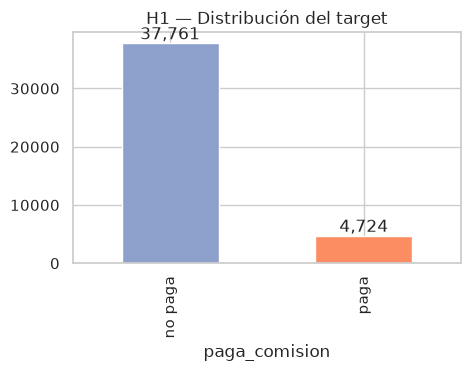

Tasa de 'paga': 11.12%


In [10]:
eda = X_train.assign(paga=y_train)

fig, ax = plt.subplots(figsize=(5, 3))
y_train.map({0: "no paga", 1: "paga"}).value_counts().plot.bar(ax=ax, color=["#8da0cb", "#fc8d62"])
ax.set_title("H1 — Distribución del target")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()
print(f"Tasa de 'paga': {y_train.mean():.2%}")

Avisos con precio en USD en el título: 7,341 (17.3%)


paga,0,1,All
title_price_over_300k,,,
0,5209,2,5211
1,1305,825,2130
All,6514,827,7341


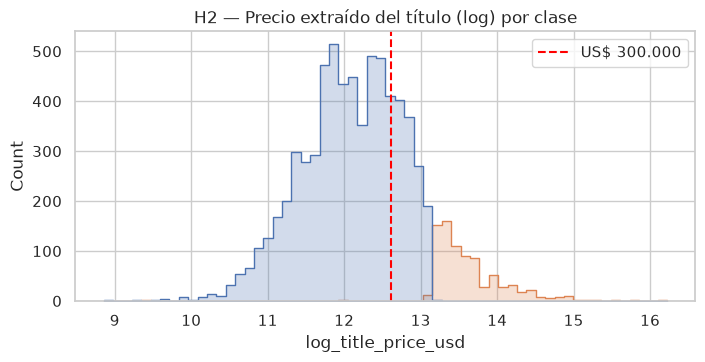

In [11]:
# H2: title price vs target
with_price = eda[eda["title_has_usd_price"] == 1]
print(f"Avisos con precio en USD en el título: {len(with_price):,} ({len(with_price) / len(eda):.1%})")
display(pd.crosstab(with_price["title_price_over_300k"], with_price["paga"], margins=True))

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(data=with_price, x="log_title_price_usd", hue="paga", bins=60, ax=ax, element="step")
ax.axvline(np.log1p(300_000), color="red", ls="--", label="US$ 300.000")
ax.set_title("H2 — Precio extraído del título (log) por clase")
ax.legend()
plt.show()

**H2 confirmada parcialmente:** por debajo de US$ 300.000 casi nunca paga; por encima, la proporción de "paga" sube muchísimo pero no es 100% (el precio publicado no siempre es el precio final de venta). Además, solo ~17% de los avisos tiene precio en el título: el modelo tiene que aprender del resto de las variables para la mayoría de los casos.

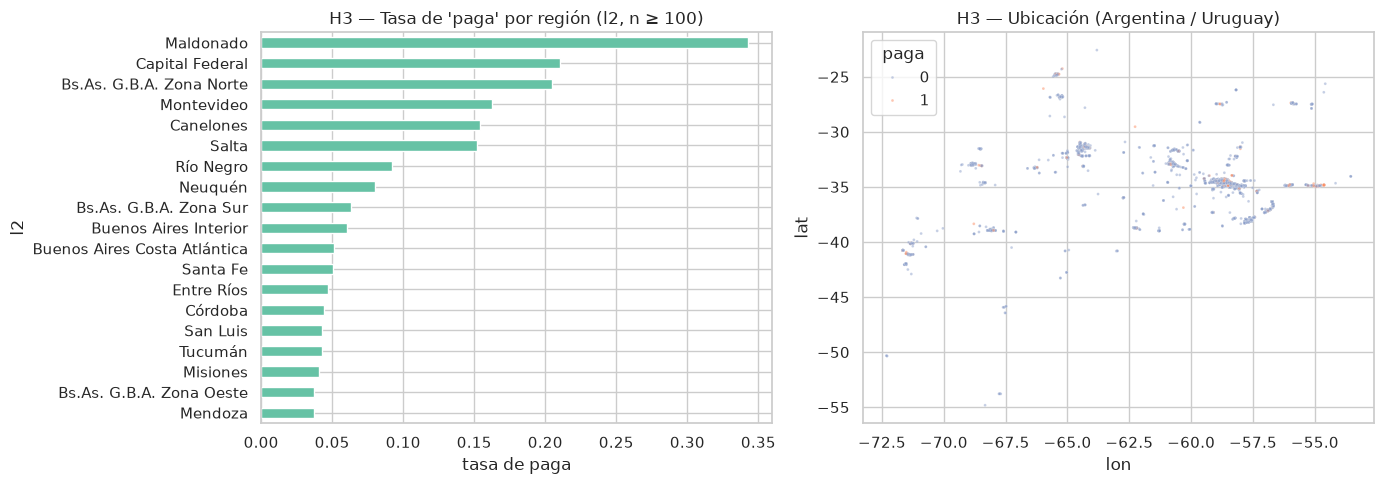

Cantidad de ciudades (l3): 508 | barrios (l4): 635


,mean,size
l3,,
Belgrano,0.766917,133
Palermo,0.736486,148
Punta Ballena,0.484536,97
San Isidro,0.406768,1448
Almagro,0.400000,55
Cariló,0.352941,68
Villa Urquiza,0.333333,90
Tigre,0.326812,3476
Punta del Este,0.319239,473


In [12]:
# H3: location
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_l2 = eda.groupby("l2")["paga"].agg(["mean", "size"]).query("size >= 100").sort_values("mean")
by_l2["mean"].plot.barh(ax=axes[0], color="#66c2a5")
axes[0].set_title("H3 — Tasa de 'paga' por región (l2, n ≥ 100)")
axes[0].set_xlabel("tasa de paga")

geo = eda.dropna(subset=["lat", "lon"]).query("-56 < lat < -21 and -74 < lon < -53")
sns.scatterplot(data=geo.sample(min(15_000, len(geo)), random_state=SEED), x="lon", y="lat",
                hue="paga", s=4, alpha=0.5, palette={0: "#8da0cb", 1: "#fc8d62"}, ax=axes[1])
axes[1].set_title("H3 — Ubicación (Argentina / Uruguay)")
plt.tight_layout()
plt.show()

by_l3 = eda.groupby("l3")["paga"].agg(["mean", "size"]).query("size >= 50").sort_values("mean", ascending=False)
print("Cantidad de ciudades (l3):", eda["l3"].nunique(), "| barrios (l4):", eda["l4"].nunique())
by_l3.head(10)

**H3 confirmada:** la tasa de "paga" va de ~4% (Zona Oeste) a más de 30% (Maldonado). `l3` tiene cientos de categorías: un one-hot explotaría la dimensionalidad (lo advierte el enunciado). Por eso usamos **target encoding** (`TargetEncoder`, que internamente hace *cross-fitting* para no filtrar el target).

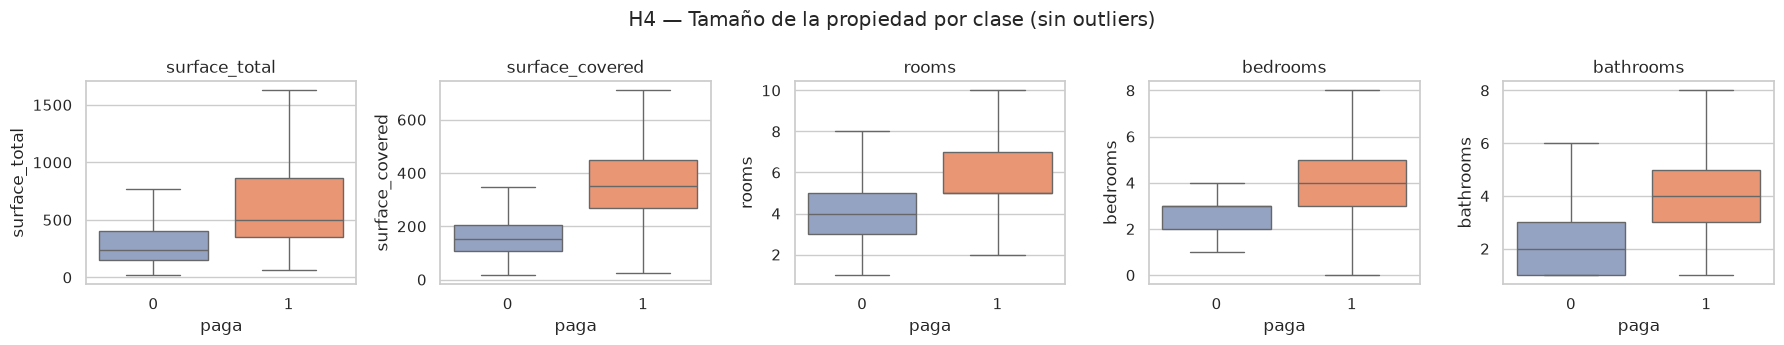

In [13]:
# H4: size variables
size_cols = ["surface_total", "surface_covered", "rooms", "bedrooms", "bathrooms"]
fig, axes = plt.subplots(1, len(size_cols), figsize=(18, 3.5))
for ax, col in zip(axes, size_cols):
    sns.boxplot(data=eda, x="paga", y=col, ax=ax, showfliers=False, palette=["#8da0cb", "#fc8d62"])
    ax.set_title(col)
fig.suptitle("H4 — Tamaño de la propiedad por clase (sin outliers)")
plt.tight_layout()
plt.show()

In [14]:
# H5: title keywords — lift over the base rate
base_rate = eda["paga"].mean()
kw = pd.DataFrame({
    "freq": eda[list(TITLE_KEYWORDS)].mean(),
    "paga_rate": [eda.loc[eda[c] == 1, "paga"].mean() for c in TITLE_KEYWORDS],
})
kw["lift"] = kw["paga_rate"] / base_rate
kw.sort_values("lift", ascending=False).style.format({"freq": "{:.1%}", "paga_rate": "{:.1%}", "lift": "{:.2f}"})

,freq,paga_rate,lift
kw_luxury,1.4%,42.4%,3.81
kw_nordelta,9.5%,29.5%,2.66
kw_gated,2.9%,19.6%,1.76
kw_view,1.6%,16.9%,1.52
kw_pool,3.8%,15.4%,1.39
kw_quinta,2.0%,13.5%,1.22
kw_lot,5.5%,11.2%,1.00
kw_garage,5.2%,10.4%,0.93
kw_park,4.4%,9.9%,0.89
kw_new,4.9%,8.8%,0.79


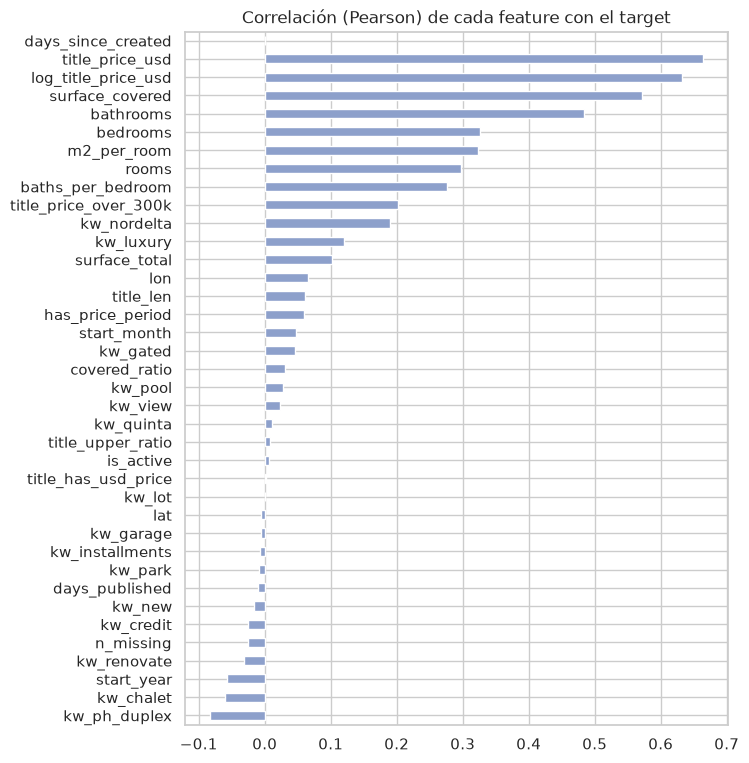

In [15]:
# Correlation of numeric features with the target
num = eda.select_dtypes("number")
num.corr()["paga"].drop("paga").sort_values().plot.barh(figsize=(7, 9), color="#8da0cb")
plt.title("Correlación (Pearson) de cada feature con el target")
plt.show()

**Conclusiones de la exploración**

1. Desbalance ~11% → usamos ganancia (no accuracy) como métrica y optimizamos el umbral.
2. El precio del título es la señal más fuerte cuando existe.
3. La ubicación importa mucho → `l1`/`l2` one-hot (pocas categorías) y `l3`/`l4` target encoding.
4. Tamaño (superficie, baños) y palabras clave (piscina, country, lujo) aportan; "cuotas"/"crédito" restan.
5. Hay muchos nulos: los imputamos con la mediana **y agregamos indicadores de nulo**, porque el dato faltante también es información.

## 5. Modelado

Un único preprocesamiento compartido + tres algoritmos:

- **Árbol de decisión** — interpretable, baseline.
- **KNN** — basado en distancias: *necesita* escalado (lo incluye el pipeline) y sufre con muchas dimensiones.
- **Random Forest** — ensamble de árboles con bagging + selección aleatoria de features; suele ser el más robusto. Es nuestro candidato principal.

Usamos `class_weight="balanced"` en los árboles para compensar el desbalance.

In [16]:
LOW_CARD_CATS = ["l1", "l2"]
HIGH_CARD_CATS = ["l3", "l4"]
GEO_CATS = list(GEO_CELL_SIZES)
TEXT_COL = "title_text"
NUMERIC = [c for c in X_train.columns if c not in LOW_CARD_CATS + HIGH_CARD_CATS + GEO_CATS + [TEXT_COL]]


def make_preprocessor(high_card_cats=HIGH_CARD_CATS, text=None):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    transformers = [
        ("num", numeric, NUMERIC),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), LOW_CARD_CATS),
        ("target_enc", TargetEncoder(target_type="binary", random_state=SEED), high_card_cats),
    ]
    if text is not None:  # A string column name hands the text transformer a 1-D Series, as TfidfVectorizer expects.
        transformers.append(("text", text, TEXT_COL))
    return ColumnTransformer(transformers)


def make_pipeline(model, high_card_cats=HIGH_CARD_CATS, text=None):
    return Pipeline([("prep", make_preprocessor(high_card_cats, text)), ("model", model)])


models = {
    "DecisionTree": make_pipeline(DecisionTreeClassifier(max_depth=8, min_samples_leaf=20,
                                                         class_weight="balanced", random_state=SEED)),
    "KNN": make_pipeline(KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1)),
    "RandomForest": make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                         class_weight="balanced_subsample",
                                                         n_jobs=-1, random_state=SEED)),
}
models["RandomForest"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('onehot', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 6. Validación

### 6.1 Validación cruzada de los modelos base

5-fold estratificado sobre el 70% de entrenamiento. Medimos **AUC** (capacidad de ordenar) y **ganancia** con el umbral por defecto 0.5 (que todavía no es el óptimo).

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "gain": gain_scorer, "f1": "f1"}

cv_rows = []
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({"model": name,
                    "auc_mean": res["test_roc_auc"].mean(), "auc_std": res["test_roc_auc"].std(),
                    "f1_mean": res["test_f1"].mean(),
                    "gain_per_fold_mean": res["test_gain"].mean(),
                    "fit_time_s": res["fit_time"].mean()})
cv_baseline = pd.DataFrame(cv_rows).set_index("model")
cv_baseline.style.format("{:.3f}", subset=["auc_mean", "auc_std", "f1_mean"]).format("{:,.0f}", subset=["gain_per_fold_mean", "fit_time_s"])

,auc_mean,auc_std,f1_mean,gain_per_fold_mean,fit_time_s
model,,,,,
DecisionTree,0.937,0.003,0.664,"46,660",1
KNN,0.929,0.005,0.570,"36,960",1
RandomForest,0.971,0.002,0.778,"63,560",6


### 6.2 Búsqueda de hiperparámetros

`RandomizedSearchCV` optimizando AUC (independiente del umbral; el umbral lo ajustamos después). Para KNN probamos varios `k` y pesos; para los árboles, profundidad y tamaño mínimo de hoja.

In [18]:
search_spaces = {
    "DecisionTree": {
        "model__max_depth": [4, 6, 8, 10, 12, 16, None],
        "model__min_samples_leaf": [5, 10, 20, 50, 100],
        "model__criterion": ["gini", "entropy"],
    },
    "KNN": {
        "model__n_neighbors": [11, 25, 51, 75, 101],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "RandomForest": {
        "model__n_estimators": [300, 500],
        "model__max_depth": [None, 20, 30],
        "model__min_samples_leaf": [1, 2, 3, 5],
        "model__max_features": ["sqrt", 0.3, 0.5],
    },
}
n_iter = {"DecisionTree": 15, "KNN": 10, "RandomForest": 10}

tuned = {}
for name, space in search_spaces.items():
    search = RandomizedSearchCV(models[name], space, n_iter=n_iter[name], scoring="roc_auc",
                                cv=cv, n_jobs=-1 if name != "RandomForest" else 2,
                                random_state=SEED, refit=True)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name:13s} AUC CV = {search.best_score_:.4f} | {search.best_params_}")

DecisionTree  AUC CV = 0.9478 | {'model__min_samples_leaf': 100, 'model__max_depth': 10, 'model__criterion': 'entropy'}


KNN           AUC CV = 0.9456 | {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 101}


RandomForest  AUC CV = 0.9709 | {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}


### 6.3 Ajuste del umbral de decisión con la función de ganancia

El umbral teórico es 1/3, pero los modelos no están perfectamente calibrados (y `class_weight="balanced"` desplaza las probabilidades). `TunedThresholdClassifierCV` busca, con validación cruzada interna, el umbral que **maximiza la ganancia**.

In [19]:
final_candidates = {}
for name, search in tuned.items():
    tuner = TunedThresholdClassifierCV(search.best_estimator_, scoring=gain_scorer, cv=cv,
                                       n_jobs=2, random_state=SEED, store_cv_results=True)
    tuner.fit(X_train, y_train)
    final_candidates[name] = tuner
    print(f"{name:13s} umbral óptimo = {tuner.best_threshold_:.3f} | ganancia CV por fold = US$ {tuner.best_score_:,.0f}")

DecisionTree  umbral óptimo = 0.798 | ganancia CV por fold = US$ 53,760


KNN           umbral óptimo = 0.242 | ganancia CV por fold = US$ 51,170


RandomForest  umbral óptimo = 0.454 | ganancia CV por fold = US$ 64,599


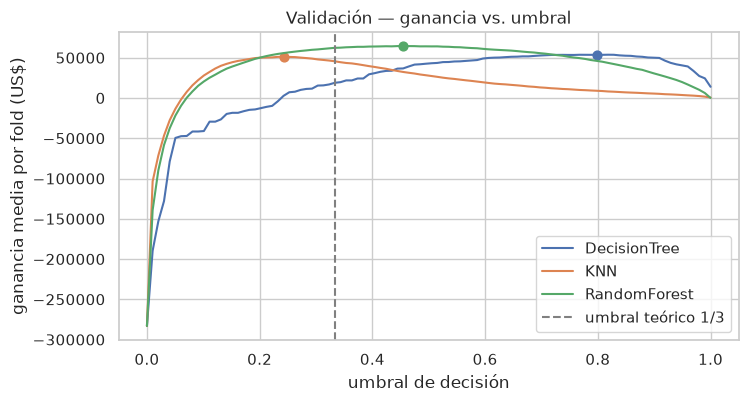

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, tuner in final_candidates.items():
    ax.plot(tuner.cv_results_["thresholds"], tuner.cv_results_["scores"], label=name)
    ax.scatter(tuner.best_threshold_, tuner.best_score_, s=40)
ax.axvline(THEORETICAL_THRESHOLD, color="grey", ls="--", label="umbral teórico 1/3")
ax.set_xlabel("umbral de decisión")
ax.set_ylabel("ganancia media por fold (US$)")
ax.set_title("Validación — ganancia vs. umbral")
ax.legend()
plt.show()

### 6.4 Variante: Random Forest con target encoding geográfico

El modelo base ya usa `lat`/`lon` como números y `l4` con target encoding. Pero un árbol necesita muchos cortes para aislar una zona chica a partir de coordenadas crudas, y `l4` falta en ~63% de los avisos. La variante discretiza `lat`/`lon` en una **grilla** (celdas de ~1 km y ~5 km) y aplica **target encoding a cada celda**: cada aviso recibe la tasa de "paga" de su vecindario, aunque no tenga barrio cargado.

Reutilizamos los hiperparámetros ganadores del Random Forest (la búsqueda es lo más costoso) y repetimos el ajuste del umbral.

In [21]:
geo_cell_counts = X_train[GEO_CATS].nunique()
print("Celdas distintas en train:", geo_cell_counts.to_dict())

rf_best_params = {k.removeprefix("model__"): v for k, v in tuned["RandomForest"].best_params_.items()}
rf_geo = make_pipeline(
    RandomForestClassifier(**rf_best_params, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    high_card_cats=HIGH_CARD_CATS + GEO_CATS,
)

res = cross_validate(rf_geo, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
print(f"RandomForest_geo AUC CV = {res['test_score'].mean():.4f} (base: {tuned['RandomForest'].best_score_:.4f})")

tuner = TunedThresholdClassifierCV(rf_geo, scoring=gain_scorer, cv=cv, n_jobs=2,
                                   random_state=SEED, store_cv_results=True)
final_candidates["RandomForest_geo"] = tuner.fit(X_train, y_train)
print(f"RandomForest_geo umbral óptimo = {tuner.best_threshold_:.3f} | ganancia CV por fold = US$ {tuner.best_score_:,.0f}")

Celdas distintas en train: {'geo_cell_1km': 5599, 'geo_cell_5km': 1163}


RandomForest_geo AUC CV = 0.9726 (base: 0.9709)


RandomForest_geo umbral óptimo = 0.434 | ganancia CV por fold = US$ 65,700


### 6.5 Variante: Random Forest con el texto del título

Las *keywords* de 3.1 las elegimos a mano, así que solo capturan lo que se nos ocurrió buscar. El título completo tiene más información: nombres de barrios y countries, estilos, cantidad de ambientes, "alquiler", etc. Para que el modelo encuentre esos términos solo, representamos el título con **TF-IDF**:

- **unigramas y bigramas** (`ngram_range=(1, 2)`), porque "barrio cerrado" o "a reciclar" dicen más que sus palabras sueltas;
- **acentos normalizados** (`strip_accents="unicode"`) y minúsculas: "Martínez" y "martinez" son el mismo término;
- `min_df` para descartar términos que aparecen en muy pocos avisos, y `sublinear_tf` para que repetir una palabra no la sobrepondere;
- va **dentro del `ColumnTransformer`**, así que el vocabulario y los pesos IDF se aprenden **solo con el train de cada fold**.

**El problema de la dimensionalidad (lo advierte el enunciado).** Meter cientos de columnas TF-IDF directo en el Random Forest no funciona bien. Con `max_features="sqrt"`, cada split sortea ~√N columnas: con 300 columnas de texto, casi todos los sorteos son términos poco frecuentes y las features fuertes (precio, ubicación, superficie) entran en menos splits. Abajo lo medimos (`RF + TF-IDF directo`).

**Solución: comprimir el texto en una sola feature.** Una **regresión logística** sobre el TF-IDF completo (es lineal y regularizada, así que maneja bien miles de columnas *sparse*) produce `title_text_score`, la probabilidad de "paga" según el título. Esa única columna entra al Random Forest junto con todas las demás, incluidas las celdas geo. Es la misma idea que el `TargetEncoder`: el score que ve el bosque en entrenamiento se calcula **out-of-fold** (`cross_val_predict`). Si no, la regresión puntuaría avisos que ya vio, el score sería demasiado optimista y el bosque confiaría de más en él. En `transform` (validación, testing, producción) se usa la regresión ajustada sobre todo el train.

También probamos `TruncatedSVD` (50 componentes) y selección por χ² (300 términos) como reducción de dimensionalidad. Quedaron por debajo del score out-of-fold, así que no las incluimos para mantener la comparación acotada.

In [22]:
class TitleTextScore(BaseEstimator, TransformerMixin):
    # TF-IDF + logistic regression compressed into one out-of-fold feature: P(paga | title).

    def __init__(self, C=2.0, min_df=3, cv=5, random_state=None):
        self.C = C
        self.min_df = min_df
        self.cv = cv
        self.random_state = random_state

    def _text_model(self):
        return Pipeline([
            ("tfidf", TfidfVectorizer(strip_accents="unicode", lowercase=True, ngram_range=(1, 2),
                                      min_df=self.min_df, sublinear_tf=True)),
            ("logreg", LogisticRegression(C=self.C, class_weight="balanced", max_iter=2000)),
        ])

    def fit(self, X, y):
        self.model_ = self._text_model().fit(X, y)
        return self

    def fit_transform(self, X, y):
        # Training rows get out-of-fold scores so the forest never sees a score the text model was fitted on.
        self.fit(X, y)
        folds = StratifiedKFold(n_splits=self.cv, shuffle=True, random_state=self.random_state)
        return cross_val_predict(self._text_model(), X, y, cv=folds, method="predict_proba")[:, 1:]

    def transform(self, X):
        return self.model_.predict_proba(X)[:, 1:]

    def get_feature_names_out(self, input_features=None):
        return np.array(["title_text_score"])


def rf_with_best_params():
    return RandomForestClassifier(**rf_best_params, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)


text_variants = {
    "RF + TF-IDF directo (300 términos)": make_pipeline(
        rf_with_best_params(), high_card_cats=HIGH_CARD_CATS + GEO_CATS,
        text=TfidfVectorizer(strip_accents="unicode", ngram_range=(1, 2), min_df=5, max_features=300, sublinear_tf=True)),
    "RandomForest_text (score out-of-fold)": make_pipeline(
        rf_with_best_params(), high_card_cats=HIGH_CARD_CATS + GEO_CATS, text=TitleTextScore(random_state=SEED)),
}

text_only = cross_validate(Pipeline([("prep", ColumnTransformer([("text", TitleTextScore(random_state=SEED), TEXT_COL)])),
                                     ("model", LogisticRegression())]),  # monotone pass-through of the score
                           X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
print(f"{'Solo el título (TF-IDF + logística)':40s} AUC CV = {text_only['test_score'].mean():.4f}")
print(f"{'RandomForest_geo (referencia)':40s} AUC CV = {res['test_score'].mean():.4f}")
for name, pipe in text_variants.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)["test_score"]
    print(f"{name:40s} AUC CV = {scores.mean():.4f} ± {scores.std():.4f}")

Solo el título (TF-IDF + logística)      AUC CV = 0.9044
RandomForest_geo (referencia)            AUC CV = 0.9726


RF + TF-IDF directo (300 términos)       AUC CV = 0.9732 ± 0.0018


RandomForest_text (score out-of-fold)    AUC CV = 0.9750 ± 0.0013


In [23]:
tuner = TunedThresholdClassifierCV(text_variants["RandomForest_text (score out-of-fold)"], scoring=gain_scorer,
                                   cv=cv, n_jobs=2, random_state=SEED, store_cv_results=True)
final_candidates["RandomForest_text"] = tuner.fit(X_train, y_train)
print(f"RandomForest_text umbral óptimo = {tuner.best_threshold_:.3f} | ganancia CV por fold = US$ {tuner.best_score_:,.0f}")

RandomForest_text umbral óptimo = 0.434 | ganancia CV por fold = US$ 67,640


**Lectura.** El título por sí solo ya ordena bastante bien (AUC alto para un único campo de texto), pero gran parte de esa señal ya la capturaban el precio extraído y las keywords. Por eso:

- **TF-IDF directo** apenas mueve el AUC respecto del modelo geo (0,9732 vs. 0,9726, menos que el desvío entre folds de ±0,0018): agrega 300 columnas para casi nada, que es justamente el problema de dimensionalidad.
- **El score out-of-fold** suma una sola columna que resume todo el vocabulario y sube el AUC de validación.

La decisión de pasar `RandomForest_text` a testing se toma con estos números de **validación cruzada**, no mirando el 30% de testing.

## 7. Testing

Aplicamos los modelos candidatos (con sus hiperparámetros y umbrales ya fijados) sobre el **30% reservado** que nunca participó del entrenamiento ni de la validación. Esta es la estimación honesta de cómo se va a comportar el modelo en datos nuevos. Referencia del enunciado: ~US$ 166.000.

In [24]:
test_rows = []
for name, model in final_candidates.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    test_rows.append({"model": name, "auc": roc_auc_score(y_test, proba), "threshold": model.best_threshold_,
                      "TP": tp, "FP": fp, "FN": fn, "gain_usd": gain(y_test, pred),
                      "gain_at_0.5": gain(y_test, (proba >= 0.5).astype(int))})
test_results = pd.DataFrame(test_rows).set_index("model").sort_values("gain_usd", ascending=False)
test_results.style.format({"auc": "{:.4f}", "threshold": "{:.3f}", "gain_usd": "US$ {:,.0f}", "gain_at_0.5": "US$ {:,.0f}"})

,auc,threshold,TP,FP,FN,gain_usd,gain_at_0.5
model,,,,,,,
RandomForest_text,0.9753,0.434,1680,474,345,"US$ 144,300","US$ 141,300"
RandomForest_geo,0.9721,0.434,1660,515,365,"US$ 140,250","US$ 138,350"
RandomForest,0.9701,0.454,1631,505,394,"US$ 137,850","US$ 136,950"
DecisionTree,0.9431,0.798,1552,731,473,"US$ 118,650","US$ 99,400"
KNN,0.9432,0.242,1428,677,597,"US$ 108,950","US$ 63,750"


Mejor modelo en testing: RandomForest_text


              precision    recall  f1-score   support

     no paga       0.98      0.97      0.97     16184
        paga       0.78      0.83      0.80      2025

    accuracy                           0.96     18209
   macro avg       0.88      0.90      0.89     18209
weighted avg       0.96      0.96      0.96     18209



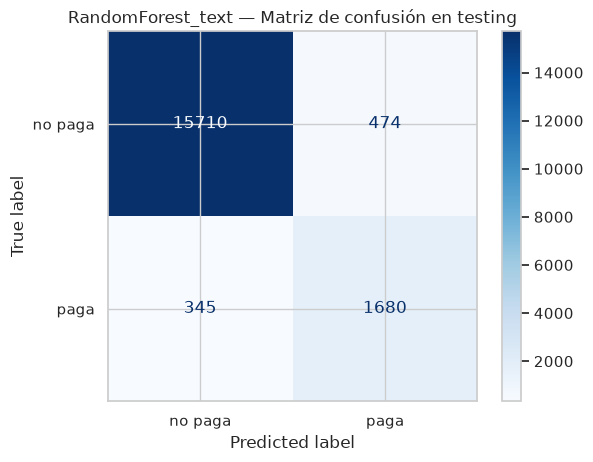

In [25]:
best_name = test_results.index[0]
best_model = final_candidates[best_name]
print("Mejor modelo en testing:", best_name)

pred_best = best_model.predict(X_test)
print(classification_report(y_test, pred_best, target_names=["no paga", "paga"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=["no paga", "paga"], cmap="Blues")
plt.title(f"{best_name} — Matriz de confusión en testing")
plt.show()

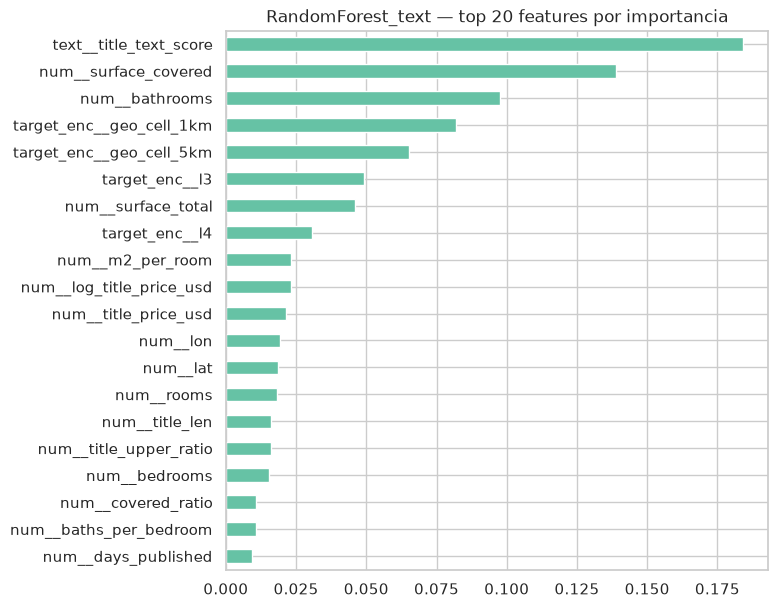

In [26]:
# What does the best Random Forest look at? (impurity-based importances)
best_rf_name = next(m for m in test_results.index if m.startswith("RandomForest"))
rf_pipe = final_candidates[best_rf_name].estimator_
feature_names = rf_pipe.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=feature_names)
importances.sort_values().tail(20).plot.barh(figsize=(7, 7), color="#66c2a5")
plt.title(f"{best_rf_name} — top 20 features por importancia")
plt.show()

## 8. Puesta en producción (entregable)

1. **Reentrenamos** el mejor modelo con el **100%** de `casas_entrenamiento.csv` (mismos hiperparámetros, más datos).
2. Fijamos el umbral validado (no lo volvemos a buscar).
3. Predecimos `casas_predecir.csv` y guardamos **solo los ids predichos como "paga"** en `casas_entrega.csv`.
4. Verificamos que los ids pertenezcan a `casas_predecir.csv` y no al entrenamiento.

Como se pueden entregar dos archivos, usamos las **dos mejores variantes de Random Forest en testing**: la primera va a `casas_entrega.csv` y la segunda a `casas_entrega_2.csv`.

In [27]:
from sklearn.base import clone
from sklearn.model_selection import FixedThresholdClassifier


def fit_for_production(name):
    tuner = final_candidates[name]
    production = FixedThresholdClassifier(clone(tuner.estimator), threshold=tuner.best_threshold_)
    return production.fit(X_full, y_full)


def export_delivery(model, path):
    pred = model.predict(X_predict)
    delivery = pd.DataFrame({"id": X_predict.index[pred == 1]})
    assert delivery["id"].isin(predict_raw.index).all(), "IDs must come from casas_predecir.csv"
    assert not delivery["id"].isin(train_raw.index).any(), "Model applied to the TRAINING set by mistake"
    delivery.to_csv(path, index=False)
    print(f"{path}: {len(delivery):,} casas predichas como 'paga' ({len(delivery) / len(X_predict):.2%} del total)")
    return delivery


production_model = fit_for_production(best_name)
delivery = export_delivery(production_model, "casas_entrega.csv")

rf_variants = [m for m in test_results.index if m.startswith("RandomForest") and m != best_name]
second_name = rf_variants[0] if rf_variants else test_results.index[1]
delivery_2 = export_delivery(fit_for_production(second_name), "casas_entrega_2.csv")
print("Archivo 1:", best_name, "| Archivo 2:", second_name)
delivery.head()

casas_entrega.csv: 4,745 casas predichas como 'paga' (11.56% del total)


casas_entrega_2.csv: 4,830 casas predichas como 'paga' (11.76% del total)
Archivo 1: RandomForest_text | Archivo 2: RandomForest_geo


,id
0,lhXkg2in7fvNqT4kYwu7eQ==
1,FnpmEp/Q5TPcY7tXJpSOZA==
2,idfOLFITsmAsXvnlE409Wg==
3,rGeUOykJC6l5eLEt+0lvWA==
4,hx+zvTEout7mE0Qo3sAJzw==


## 9. Seguimiento y recalibración

Una vez en producción el modelo se degrada (cambia el mercado inmobiliario, el tipo de cambio, el formato de los avisos). Propuesta:

- **Seguimiento:** cada período (p.ej. mensual) comparar la ganancia real (100·TP − 50·FP) contra la esperada en testing, y la proporción de casas marcadas como "paga" contra la tasa histórica (~11%). Monitorear también *data drift* de las features clave: precio en el título, `l2`, superficies.
- **Recalibración:** si la ganancia cae por debajo de un umbral acordado o hay drift significativo, reentrenar con los datos más recientes reutilizando este mismo pipeline (la transformación y el modelo están encapsulados en `build_features` + `Pipeline`, así que reentrenar es volver a ejecutar las etapas 5 a 8).